In [6]:
# Experiment 10: Intelligent Decision Support System
# Application: a low-stakes student learning-support recommender.
# This classroom demo uses synthetic examples only; it is not for real student decisions.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, classification_report

np.random.seed(10)
FEATURES = ["quiz_score", "study_hours", "missed_tasks", "reliable_internet"]

# 1. EXPERT SYSTEM: knowledge base plus forward-chaining inference.
KNOWLEDGE_BASE = {
    "focused_score_max": 55,
    "focused_missed_min": 3,
    "guided_score_max": 75,
    "guided_hours_max": 3,
}

def expert_recommendation(profile, rules=KNOWLEDGE_BASE):
    score = profile["quiz_score"]
    hours = profile["study_hours"]
    missed = profile["missed_tasks"]
    fired = []
    if score <= rules["focused_score_max"]:
        level = "Focused support"
        fired.append(f"R1: quiz score <= {rules['focused_score_max']}")
    elif missed >= rules["focused_missed_min"]:
        level = "Focused support"
        fired.append(f"R2: missed tasks >= {rules['focused_missed_min']}")
    elif score <= rules["guided_score_max"] or hours < rules["guided_hours_max"]:
        level = "Guided practice"
        if score <= rules["guided_score_max"]:
            fired.append(f"R3: quiz score <= {rules['guided_score_max']}")
        if hours < rules["guided_hours_max"]:
            fired.append(f"R4: study hours < {rules['guided_hours_max']}")
    else:
        level = "Independent study"
        fired.append("R5: no focused or guided-support rule fired")
    resource = "Downloadable / offline study pack" if profile["reliable_internet"] == 0 else "Online practice and tutor links"
    fired.append("R6: resource format follows internet access; support level does not")
    return {"Recommendation": level, "Resource": resource, "Explanation": fired}

# Example cases used in the rule-based demonstration.
example_profiles = [
    {"quiz_score": 48, "study_hours": 2, "missed_tasks": 3, "reliable_internet": 1},
    {"quiz_score": 68, "study_hours": 2, "missed_tasks": 1, "reliable_internet": 0},
    {"quiz_score": 91, "study_hours": 6, "missed_tasks": 0, "reliable_internet": 1},
]
print("Experiment 10 — Intelligent Decision Support System")
print("Expert knowledge base and inference engine are defined.")


Experiment 10 — Intelligent Decision Support System
Expert knowledge base and inference engine are defined.


In [7]:
# 2. RECOMMENDATIONS AND EXPLANATION FACILITY
rule_rows = []
for profile in example_profiles:
    result = expert_recommendation(profile)
    rule_rows.append({**profile, "Recommendation": result["Recommendation"], "Resource": result["Resource"]})
    print("\nInput:", profile)
    print("Recommendation:", result["Recommendation"])
    print("Resource:", result["Resource"])
    print("Why:")
    for reason in result["Explanation"]:
        print(" -", reason)
print("\nSummary of rule-based recommendations:")
print(pd.DataFrame(rule_rows).to_string(index=False))



Input: {'quiz_score': 48, 'study_hours': 2, 'missed_tasks': 3, 'reliable_internet': 1}
Recommendation: Focused support
Resource: Online practice and tutor links
Why:
 - R1: quiz score <= 55
 - R6: resource format follows internet access; support level does not

Input: {'quiz_score': 68, 'study_hours': 2, 'missed_tasks': 1, 'reliable_internet': 0}
Recommendation: Guided practice
Resource: Downloadable / offline study pack
Why:
 - R3: quiz score <= 75
 - R4: study hours < 3
 - R6: resource format follows internet access; support level does not

Input: {'quiz_score': 91, 'study_hours': 6, 'missed_tasks': 0, 'reliable_internet': 1}
Recommendation: Independent study
Resource: Online practice and tutor links
Why:
 - R5: no focused or guided-support rule fired
 - R6: resource format follows internet access; support level does not

Summary of rule-based recommendations:
 quiz_score  study_hours  missed_tasks  reliable_internet    Recommendation                          Resource
         48   

In [8]:
# 3. IMITATION LEARNING FROM LABELED EXAMPLE DECISIONS
# Synthetic demonstration decisions make this notebook reproducible; replace with real annotations for a real study.
def create_human_examples(n=800, seed=11, corrected=False):
    rng = np.random.default_rng(seed)
    data = pd.DataFrame({
        "quiz_score": rng.integers(30, 101, n),
        "study_hours": rng.integers(0, 9, n),
        "missed_tasks": rng.integers(0, 6, n),
        "reliable_internet": rng.integers(0, 2, n),
    })
    underlying_need = ((data.quiz_score <= 60) | (data.missed_tasks >= 3) | (data.study_hours < 2))
    if corrected:
        decisions = underlying_need.copy()
    else:
        # Simulated initial assessor examples: high-need students with limited internet
        # are less often recommended support. This intentional flaw is audited below.
        decisions = underlying_need & (data.reliable_internet == 1)
    data["recommend_support"] = decisions.astype(int)
    return data

examples = create_human_examples()
X = examples[FEATURES]
y = examples["recommend_support"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10, stratify=y
)
imitation_model = DecisionTreeClassifier(max_depth=5, random_state=10)
imitation_model.fit(X_train, y_train)
predictions = imitation_model.predict(X_test)
print("3. IMITATION LEARNING")
print(f"Labeled examples: {len(examples)} (training={len(X_train)}, test={len(X_test)})")
print(f"Test accuracy against example decisions: {accuracy_score(y_test, predictions):.3f}")
print(classification_report(y_test, predictions, target_names=["No support", "Recommend support"], zero_division=0))
print("Decision-tree explanation rules (input factors used by the learned model):")
print(export_text(imitation_model, feature_names=FEATURES))


3. IMITATION LEARNING
Labeled examples: 800 (training=600, test=200)
Test accuracy against example decisions: 1.000
                   precision    recall  f1-score   support

       No support       1.00      1.00      1.00       118
Recommend support       1.00      1.00      1.00        82

         accuracy                           1.00       200
        macro avg       1.00      1.00      1.00       200
     weighted avg       1.00      1.00      1.00       200

Decision-tree explanation rules (input factors used by the learned model):
|--- reliable_internet <= 0.50
|   |--- class: 0
|--- reliable_internet >  0.50
|   |--- missed_tasks <= 2.50
|   |   |--- quiz_score <= 60.50
|   |   |   |--- class: 1
|   |   |--- quiz_score >  60.50
|   |   |   |--- study_hours <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- study_hours >  1.50
|   |   |   |   |--- class: 0
|   |--- missed_tasks >  2.50
|   |   |--- class: 1



In [9]:
# 4. ETHICAL AI: group-level and matched-profile fairness audit
# Groups are access conditions (limited vs reliable internet), not demographic labels.
FAIR_FEATURES = ["quiz_score", "study_hours", "missed_tasks"]
corrected_examples = create_human_examples(n=800, seed=11, corrected=True)
corrected_model = DecisionTreeClassifier(max_depth=5, random_state=10)
corrected_model.fit(corrected_examples[FAIR_FEATURES], corrected_examples["recommend_support"])

# Paired audit: each learning profile appears once in each access group.
rng = np.random.default_rng(99)
profiles = pd.DataFrame({
    "quiz_score": rng.integers(30, 101, 500),
    "study_hours": rng.integers(0, 9, 500),
    "missed_tasks": rng.integers(0, 6, 500),
})
audit = pd.concat([profiles.assign(reliable_internet=0), profiles.assign(reliable_internet=1)], ignore_index=True)
audit["profile_id"] = np.tile(np.arange(len(profiles)), 2)
audit["need"] = ((audit.quiz_score <= 60) | (audit.missed_tasks >= 3) | (audit.study_hours < 2)).astype(int)
audit["initial_model"] = imitation_model.predict(audit[FEATURES])
audit["corrected_model"] = corrected_model.predict(audit[FAIR_FEATURES])

def group_metrics(frame, prediction_column):
    rows = []
    for access, label in [(0, "Limited internet"), (1, "Reliable internet")]:
        subset = frame[frame.reliable_internet == access]
        positive = subset[prediction_column] == 1
        need = subset.need == 1
        tpr = (positive & need).sum() / max(1, need.sum())
        rows.append({"Group": label, "Support recommendation rate (%)": 100 * positive.mean(),
                     "True-positive rate for high need (%)": 100 * tpr})
    return pd.DataFrame(rows)

initial_fairness = group_metrics(audit, "initial_model")
corrected_fairness = group_metrics(audit, "corrected_model")
paired_initial = audit.pivot(index="profile_id", columns="reliable_internet", values="initial_model")
paired_corrected = audit.pivot(index="profile_id", columns="reliable_internet", values="corrected_model")
print("4. ETHICAL AI AUDIT")
print("Initial imitation model group metrics:")
print(initial_fairness.round(1).to_string(index=False))
print("\nCorrected-example model group metrics:")
print(corrected_fairness.round(1).to_string(index=False))
print(f"\nMatched-profile recommendations changed by access condition (initial): {(paired_initial[0] != paired_initial[1]).mean()*100:.1f}%")
print(f"Matched-profile recommendations changed by access condition (corrected): {(paired_corrected[0] != paired_corrected[1]).mean()*100:.1f}%")
print("Transparency note: support uses learning indicators; access only selects resource format in the expert rules.")


4. ETHICAL AI AUDIT
Initial imitation model group metrics:
            Group  Support recommendation rate (%)  True-positive rate for high need (%)
 Limited internet                              0.0                                   0.0
Reliable internet                             80.0                                 100.0

Corrected-example model group metrics:
            Group  Support recommendation rate (%)  True-positive rate for high need (%)
 Limited internet                             80.0                                 100.0
Reliable internet                             80.0                                 100.0

Matched-profile recommendations changed by access condition (initial): 80.0%
Matched-profile recommendations changed by access condition (corrected): 0.0%
Transparency note: support uses learning indicators; access only selects resource format in the expert rules.


5. RULE CHANGE COMPARISON
Input profile: {'quiz_score': 60, 'study_hours': 4, 'missed_tasks': 1, 'reliable_internet': 0}
Before: Guided practice — R3: quiz score <= 75; R6: resource format follows internet access; support level does not
After:  Focused support — R1: quiz score <= 65; R6: resource format follows internet access; support level does not

Imitation model comparison on paired audit profiles:
                                  Model  Accuracy vs. need target
Initial examples (access-linked labels)                       0.6
 Corrected examples (need-based labels)                       1.0

Matched-profile recommendations changed by access (initial): 80.0%
Matched-profile recommendations changed by access (corrected): 0.0%


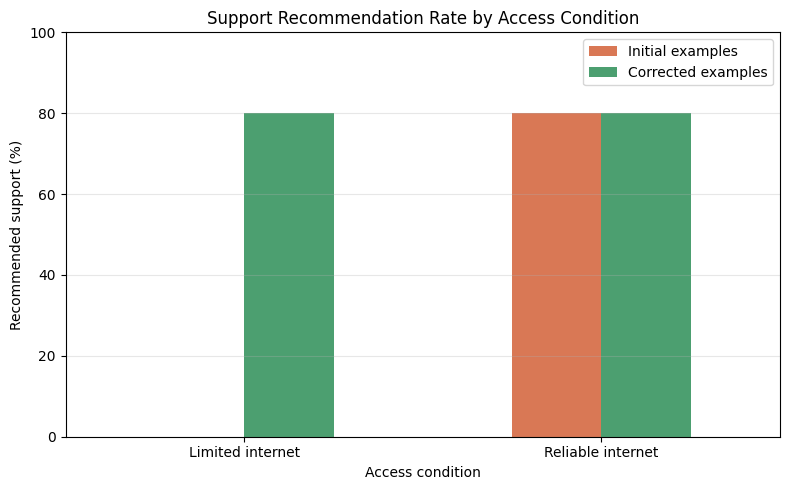


OBSERVATIONS
1. The rule engine displays which knowledge-base conditions caused each recommendation.
2. The decision tree imitates labeled examples and exposes its learned input thresholds.
3. Group rates and matched-profile tests reveal the effect of access-linked example labels.
4. Correcting labels and excluding access from the support model reduces this source of disparity.
5. The rule-change example shows how updating the knowledge base changes a recommendation.


In [10]:
# 5. TESTING AND COMPARISON: change a rule and example decisions
REVISED_KNOWLEDGE_BASE = {**KNOWLEDGE_BASE, "focused_score_max": 65, "guided_score_max": 80}
comparison_profile = {"quiz_score": 60, "study_hours": 4, "missed_tasks": 1, "reliable_internet": 0}
before_rule = expert_recommendation(comparison_profile, KNOWLEDGE_BASE)
after_rule = expert_recommendation(comparison_profile, REVISED_KNOWLEDGE_BASE)
print("5. RULE CHANGE COMPARISON")
print("Input profile:", comparison_profile)
print("Before:", before_rule["Recommendation"], "—", "; ".join(before_rule["Explanation"]))
print("After: ", after_rule["Recommendation"], "—", "; ".join(after_rule["Explanation"]))

# Re-pair identical profiles for a counterfactual check of the access feature.
audit["profile_id"] = np.tile(np.arange(len(profiles)), 2)
paired_initial = audit.pivot(index="profile_id", columns="reliable_internet", values="initial_model")
paired_corrected = audit.pivot(index="profile_id", columns="reliable_internet", values="corrected_model")
# Compare the initial model and corrected-example model on the same need-based audit target.
initial_accuracy = accuracy_score(audit.need, audit.initial_model)
corrected_accuracy = accuracy_score(audit.need, audit.corrected_model)
print("\nImitation model comparison on paired audit profiles:")
print(pd.DataFrame([
    {"Model": "Initial examples (access-linked labels)", "Accuracy vs. need target": initial_accuracy},
    {"Model": "Corrected examples (need-based labels)", "Accuracy vs. need target": corrected_accuracy},
]).round(3).to_string(index=False))
print(f"\nMatched-profile recommendations changed by access (initial): {(paired_initial[0] != paired_initial[1]).mean()*100:.1f}%")
print(f"Matched-profile recommendations changed by access (corrected): {(paired_corrected[0] != paired_corrected[1]).mean()*100:.1f}%")

plot_data = pd.DataFrame({
    "Initial examples": initial_fairness.set_index("Group")["Support recommendation rate (%)"],
    "Corrected examples": corrected_fairness.set_index("Group")["Support recommendation rate (%)"],
})
plot_data.plot(kind="bar", figsize=(8, 5), ylim=(0, 100), color=["#d97855", "#4c9f70"])
plt.title("Support Recommendation Rate by Access Condition")
plt.ylabel("Recommended support (%)")
plt.xlabel("Access condition")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nOBSERVATIONS")
print("1. The rule engine displays which knowledge-base conditions caused each recommendation.")
print("2. The decision tree imitates labeled examples and exposes its learned input thresholds.")
print("3. Group rates and matched-profile tests reveal the effect of access-linked example labels.")
print("4. Correcting labels and excluding access from the support model reduces this source of disparity.")
print("5. The rule-change example shows how updating the knowledge base changes a recommendation.")
